In [1]:
import sys
sys.path.append("..")

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from clean_data import feature_engineering

In [2]:
df= pd.read_csv("../data/austin/raw/aac_intakes_outcomes.csv")

# Exploratory Data Analysis (EDA)

This notebook focuses on exploring the Austin Animal Center dataset, analyzing animal characteristics, intake patterns, and shelter outcomes to identify potential relationships and support further predictive modeling.

## Dataframe Info

In [3]:
# Initial exploratory analysis provides an overview
# of the dataset structure, missing values, and
# distributions of key animal and intake characteristics.

# These findings will guide data preprocessing,
# feature engineering, and model selection.

df.head()

,age_upon_outcome,animal_id_outcome,date_of_birth,outcome_subtype,outcome_type,sex_upon_outcome,age_upon_outcome_(days),age_upon_outcome_(years),age_upon_outcome_age_group,outcome_datetime,...,age_upon_intake_age_group,intake_datetime,intake_month,intake_year,intake_monthyear,intake_weekday,intake_hour,intake_number,time_in_shelter,time_in_shelter_days
0,10 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,3650,10.0,"(7.5, 10.0]",2017-12-07 14:07:00,...,"(7.5, 10.0]",2017-12-07 00:00:00,12,2017,2017-12,Thursday,14,1.0,0 days 14:07:00.000000000,0.588194
1,7 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,2555,7.0,"(5.0, 7.5]",2014-12-20 16:35:00,...,"(5.0, 7.5]",2014-12-19 10:21:00,12,2014,2014-12,Friday,10,2.0,1 days 06:14:00.000000000,1.259722
2,6 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,2190,6.0,"(5.0, 7.5]",2014-03-08 17:10:00,...,"(5.0, 7.5]",2014-03-07 14:26:00,3,2014,2014-03,Friday,14,3.0,1 days 02:44:00.000000000,1.113889
3,10 years,A047759,2004-04-02 00:00:00,Partner,Transfer,Neutered Male,3650,10.0,"(7.5, 10.0]",2014-04-07 15:12:00,...,"(7.5, 10.0]",2014-04-02 15:55:00,4,2014,2014-04,Wednesday,15,1.0,4 days 23:17:00.000000000,4.970139
4,16 years,A134067,1997-10-16 00:00:00,NaN,Return to Owner,Neutered Male,5840,16.0,"(15.0, 17.5]",2013-11-16 11:54:00,...,"(15.0, 17.5]",2013-11-16 09:02:00,11,2013,2013-11,Saturday,9,1.0,0 days 02:52:00.000000000,0.119444


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79672 entries, 0 to 79671
Data columns (total 41 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age_upon_outcome            79672 non-null  object 
 1   animal_id_outcome           79672 non-null  object 
 2   date_of_birth               79672 non-null  object 
 3   outcome_subtype             36348 non-null  object 
 4   outcome_type                79662 non-null  object 
 5   sex_upon_outcome            79671 non-null  object 
 6   age_upon_outcome_(days)     79672 non-null  int64  
 7   age_upon_outcome_(years)    79672 non-null  float64
 8   age_upon_outcome_age_group  79672 non-null  object 
 9   outcome_datetime            79672 non-null  object 
 10  outcome_month               79672 non-null  int64  
 11  outcome_year                79672 non-null  int64  
 12  outcome_monthyear           79672 non-null  object 
 13  outcome_weekday             796

In [5]:
#How many null in suspicious columns?
print(df.isnull().sum()[df.isnull().sum() > 0])

outcome_subtype     43324
outcome_type           10
sex_upon_outcome        1
sex_upon_intake         1
dtype: int64


In [6]:
# Length of stay is calculated from historical shelter records.
# It may serve as a target for regression or long-stay
# risk classification.

# Since actual length of stay is only known after an animal
# leaves the shelter, using it to predict outcome_type
# at intake would introduce data leakage.

# An alternative is to use predicted length of stay
# from a regression model as an additional feature
# for outcome classification (two-stage modeling).

df["days_in_shelters"] = pd.to_timedelta(df["time_in_shelter"]).dt.days

In [7]:
print(df.duplicated().sum())

35


In [8]:
# The distribution of outcome types should be examined
# to identify potential class imbalance.

# Accuracy alone may not be sufficient to evaluate
# classification performance. Macro F1-score and
# per-class metrics should be considered.

df["outcome_type"].value_counts()

outcome_type
Adoption           33594
Transfer           23799
Return to Owner    14791
Euthanasia          6244
Died                 690
Disposal             304
Rto-Adopt            179
Missing               46
Relocate              15
Name: count, dtype: int64

In [9]:
#What is the percent?
df['animal_type'].value_counts(normalize=True)*100

animal_type
Dog      56.940958
Cat      37.075761
Other     5.557787
Bird      0.425495
Name: proportion, dtype: float64

In [10]:
df["intake_condition"].value_counts(normalize=True)*100

intake_condition
Normal      87.930515
Injured      5.016819
Sick         3.889698
Nursing      2.403605
Aged         0.400392
Other        0.184506
Feral        0.115473
Pregnant     0.058992
Name: proportion, dtype: float64

In [11]:
df["is_mixed_breed"] = df["breed"].str.contains("/|Mix", na=False).astype(int)
df["primary_breed"] = df["breed"].str.split("/|Mix").str[0].str.strip()

top_breeds = df["primary_breed"].value_counts().head(4).index
df["primary_breed_top"] = df["primary_breed"].where(
    df["primary_breed"].isin(top_breeds), "Other")

df["primary_breed_top"].value_counts(normalize=True)*100

primary_breed_top
Other                  46.445426
Domestic Shorthair     29.893815
Pit Bull                8.616578
Labrador Retriever      7.857215
Chihuahua Shorthair     7.186967
Name: proportion, dtype: float64

In [12]:
df["intake_type"].value_counts(normalize=True)*100

intake_type
Stray                 70.206597
Owner Surrender       18.862336
Public Assist          6.268200
Wildlife               4.347826
Euthanasia Request     0.315042
Name: proportion, dtype: float64

In [13]:
top_location = (df["found_location"].value_counts().head(10).reset_index())
top_location.columns = ["Location", "Count"]
top_location

,Location,Count
0,Austin (TX),14311
1,Outside Jurisdiction,945
2,Travis (TX),907
3,7201 Levander Loop in Austin (TX),514
4,Del Valle (TX),407
5,Pflugerville (TX),370
6,Manor (TX),268
7,4434 Frontier Trl in Austin (TX),162
8,124 W Anderson Ln in Austin (TX),152
9,Leander (TX),112


In [14]:
df["sex_upon_intake"].value_counts(normalize=True)*100

sex_upon_intake
Intact Male      31.776933
Intact Female    29.752357
Neutered Male    15.950597
Spayed Female    13.998820
Unknown           8.521294
Name: proportion, dtype: float64

In [15]:
df["breed"].value_counts(normalize=True)*100

breed
Domestic Shorthair Mix      29.399287
Pit Bull Mix                 7.852194
Chihuahua Shorthair Mix      6.063611
Labrador Retriever Mix       6.010895
Domestic Medium Hair Mix     2.919470
                              ...    
American                     0.001255
Belgian Hare                 0.001255
Rottweiler/Boxer             0.001255
Plott Hound/Beagle           0.001255
Britannia Petit Mix          0.001255
Name: proportion, Length: 2155, dtype: float64

In [16]:
#What outcomes?
df["outcome_type"].value_counts(normalize=True)*100

outcome_type
Adoption           42.170671
Transfer           29.874972
Return to Owner    18.567196
Euthanasia          7.838116
Died                0.866160
Disposal            0.381612
Rto-Adopt           0.224699
Missing             0.057744
Relocate            0.018830
Name: proportion, dtype: float64

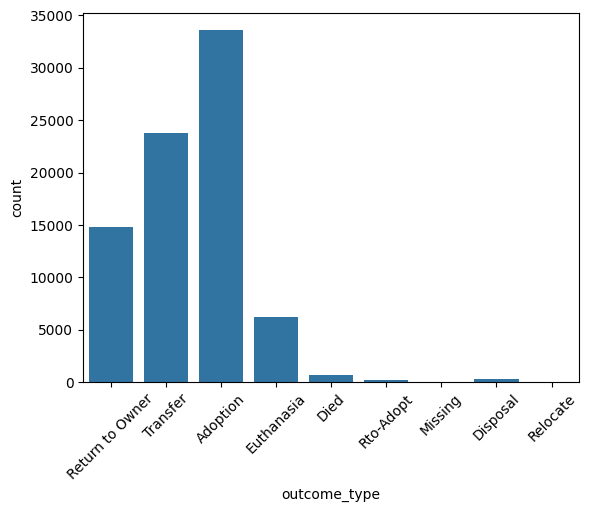

In [17]:
sns.countplot(x="outcome_type", data=df)
plt.xticks(rotation=45)
plt.show()

## Dogs

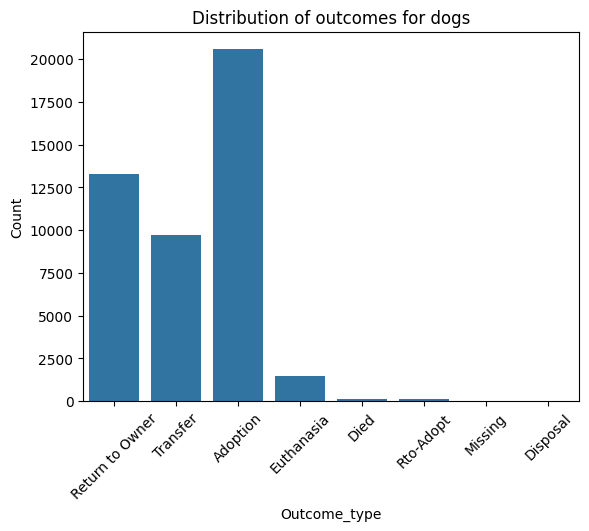

In [18]:
# The outcome distribution for dogs provides a baseline
# for understanding the relative frequency of each outcome.

sns.countplot(data=df[df["animal_type"]=="Dog"], x = "outcome_type")
plt.title("Distribution of outcomes for dogs")
plt.xlabel("Outcome_type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

In [19]:
dog_outcomes = (
    df[df["animal_type"] == "Dog"]["outcome_type"].value_counts(normalize=True).mul(100).reset_index()
)

dog_outcomes.columns = ["Outcome Type", "Percentage (%)"]
dog_outcomes["Percentage (%)"] = dog_outcomes["Percentage (%)"].round(2)
dog_outcomes

,Outcome Type,Percentage (%)
0,Adoption,45.37
1,Return to Owner,29.26
2,Transfer,21.38
3,Euthanasia,3.31
4,Rto-Adopt,0.32
5,Died,0.31
6,Missing,0.04
7,Disposal,0.02


In [20]:
df[df["animal_type"]=="Dog"]["outcome_type"].value_counts()

outcome_type
Adoption           20581
Return to Owner    13273
Transfer            9697
Euthanasia          1502
Rto-Adopt            143
Died                 142
Missing               16
Disposal              10
Name: count, dtype: int64

In [21]:
# Breed information may be relevant for outcome prediction.
# However, breed categories can be highly imbalanced,
# with many breeds represented by relatively few records.

dog_breed = (
    df[df["animal_type"] == "Dog"]["primary_breed_top"].value_counts(normalize=True).mul(100).reset_index()
)

dog_breed.columns = ["Top breed", "Percentage (%)"]
dog_breed["Percentage (%)"] = dog_breed["Percentage (%)"].round(2)
dog_breed

,Top breed,Percentage (%)
0,Other,58.45
1,Pit Bull,15.13
2,Labrador Retriever,13.80
3,Chihuahua Shorthair,12.62


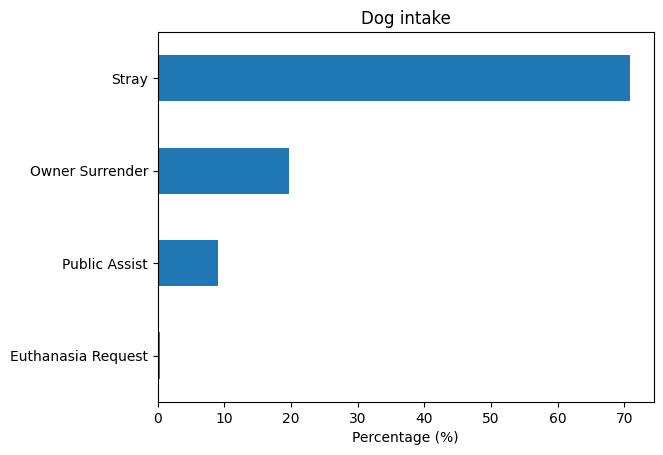

In [22]:
#What was the dogs' intake type?
dog_intake = (df[df["animal_type"]=="Dog"]["intake_type"].value_counts(normalize=True).mul(100))
dog_intake.sort_values().plot(kind="barh")
plt.xlabel("Percentage (%)")
plt.ylabel("")
plt.title("Dog intake")
plt.show()

In [23]:
dog_intake = (df[df["animal_type"]=="Dog"]["intake_type"].value_counts(normalize=True).mul(100).reset_index())
dog_intake.columns = ["Intake_type", "Percentage (%)"]
dog_intake["Percentage (%)"] = dog_intake["Percentage (%)"].round(2)
dog_intake

,Intake_type,Percentage (%)
0,Stray,70.88
1,Owner Surrender,19.67
2,Public Assist,9.04
3,Euthanasia Request,0.40


In [24]:
# This analysis examines how outcome distributions vary
# across different intake types for dogs.

# Intake type may be an informative feature for
# outcome prediction, although the observed associations
# do not imply causation.

pd.crosstab(
    df[df["animal_type"]=="Dog"]["intake_type"],
    df[df["animal_type"]=="Dog"]["outcome_type"],
    normalize="index"
).mul(100).round(2)

outcome_type,Adoption,Died,Disposal,Euthanasia,Missing,Return to Owner,Rto-Adopt,Transfer
intake_type,,,,,,,,
Euthanasia Request,2.75,1.65,0.00,80.77,0.00,2.20,0.00,12.64
Owner Surrender,57.50,0.34,0.02,5.32,0.02,6.38,0.36,30.06
Public Assist,10.53,0.20,0.05,3.66,0.02,73.96,0.29,11.29
Stray,46.69,0.31,0.02,2.27,0.04,30.06,0.31,20.30


In [25]:
# Comparing outcome distributions between dogs and cats
# helps identify potential differences between species.

# These differences may justify evaluating separate
# predictive models for dogs and cats.

dogs_cats = df[df["animal_type"].isin(["Dog", "Cat"])]
pd.crosstab(
    dogs_cats["animal_type"],
    dogs_cats["outcome_type"],
    normalize="index"
).mul(100).round(2)

outcome_type,Adoption,Died,Disposal,Euthanasia,Missing,Return to Owner,Rto-Adopt,Transfer
animal_type,,,,,,,,
Cat,42.91,1.36,0.04,4.99,0.10,4.98,0.12,45.49
Dog,45.37,0.31,0.02,3.31,0.04,29.26,0.32,21.38


In [26]:
# Intake type distributions may differ between dogs and cats,
# reflecting different circumstances of shelter admission.

# These differences should be considered when interpreting
# species-specific outcome patterns.

pd.crosstab(
    dogs_cats["animal_type"],
    dogs_cats["intake_type"],
    normalize="index"
).mul(100).round(2)

intake_type,Euthanasia Request,Owner Surrender,Public Assist,Stray
animal_type,,,,
Cat,0.2,19.52,2.27,78.01
Dog,0.4,19.67,9.04,70.88


## Cats

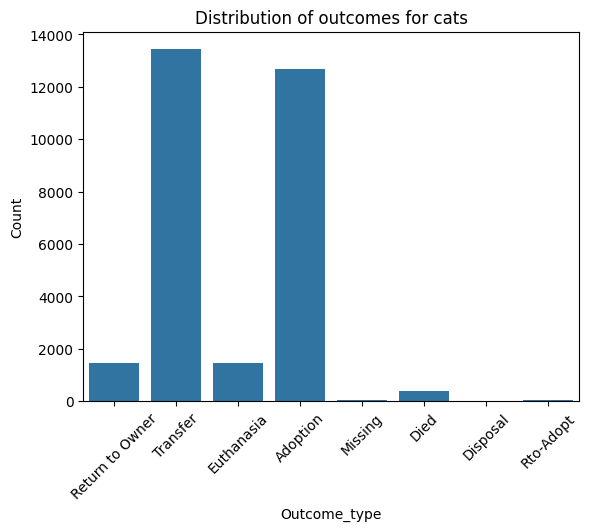

In [27]:
# The outcome distribution for cats can be compared
# with the corresponding distribution for dogs.

# Differences in class proportions may affect
# classification performance and should be considered
# when selecting evaluation metrics.

sns.countplot(data=df[df["animal_type"]=="Cat"], x = "outcome_type")
plt.title("Distribution of outcomes for cats")
plt.xlabel("Outcome_type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

In [28]:
cat_outcomes = (
    df[df["animal_type"] == "Cat"]["outcome_type"].value_counts(normalize=True).mul(100).reset_index()
)

cat_outcomes.columns = ["Outcome Type", "Percentage (%)"]
cat_outcomes["Percentage (%)"] = cat_outcomes["Percentage (%)"].round(2)
cat_outcomes

,Outcome Type,Percentage (%)
0,Transfer,45.49
1,Adoption,42.91
2,Euthanasia,4.99
3,Return to Owner,4.98
4,Died,1.36
5,Rto-Adopt,0.12
6,Missing,0.10
7,Disposal,0.04


### Preliminary Conclusions

- The initial analysis provides an overview of shelter intake characteristics and outcome distributions.
- Potential class imbalance should be considered when developing outcome classification models.
- Differences between dogs and cats suggest that species-specific modeling may be worth investigating.
- Intake-related characteristics may provide useful information for outcome prediction.
- Length of stay is a potential alternative prediction target and could also be explored as part of a two-stage modeling approach.

**Next step:** Further feature engineering and exploratory analysis will be conducted before selecting the final predictive modeling approach.